# Propagating Uncertainty: Monte Carlo vs. First-Order Second-Moment

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ahmed-Bayoumy/MECH559/blob/HEAD/L14/L14_uncertainty_propagation.ipynb)
### MECH 559 - Systems Optimization - L14
### Course Instructor: Dr. Ahmed Bayoumy
Author of the notebook: Dr. Ahmed Bayoumy

Companion notebook to the "Random variables and uncertainty propagation" slides.
An uncertain input $\mathbf X$ has to be pushed through a performance function
$Y=g(\mathbf X)$ to find out how uncertain the *output* is. This notebook builds
the random-variable refresher from the slides in code, propagates uncertainty two
ways -- brute-force Monte Carlo simulation (MCS) and the analytic first-order
second-moment (FOSM) approximation -- and shows exactly where FOSM's linearization
starts to break down.

## Learning objectives

1. Connect a random variable's PDF/CDF/mean/variance to code, and check that a
   Monte Carlo sample recovers the analytic values.
2. Propagate uncertainty through a nonlinear $g(\mathbf X)$ with MCS and with the
   FOSM mean/variance formulas, and explain why FOSM's zeroth-order mean is biased.
3. Show that adding FOSM's second-order (curvature) correction to the mean removes
   exactly the bias caused by $g$'s own curvature.
4. Demonstrate that MCS error shrinks like $N^{-1/2}$ regardless of dimension,
   while FOSM's variance error grows with the input's coefficient of variation --
   the cost/accuracy trade-off that motivates FORM/SORM (next notebook).

> **Classroom rhythm:** pause at each **Predict** prompt before running the next
> cell.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({
    "font.size": 11,
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
})
COLORS = {"true": "#264653", "mc": "#2A9D5C", "fosm": "#D1495B", "hist": "#8ab4f8"}
rng = np.random.default_rng(559)
print(f"NumPy {np.__version__}")

NumPy 2.5.2


---
## 1. A random variable: sampling vs. the analytic PDF

$X_1\sim\mathcal N(\mu_1,\sigma_1^2)$ could model, e.g., a manufactured dimension
whose true value scatters around its nominal (mean) value $\mu_1$ with standard
deviation $\sigma_1$ (slide "Random variables: brief refresher").

> **Predict:** with only 20,000 samples, will the sample mean and sample standard
> deviation match $\mu_1=3.0$ and $\sigma_1=0.3$ closely, or only roughly?

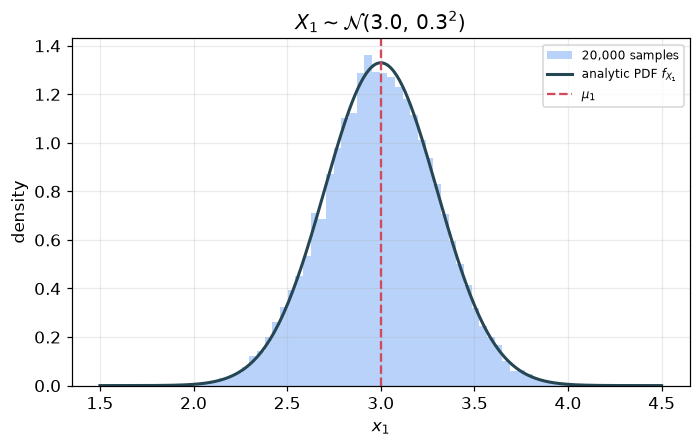

sample mean = 2.9989  (true mu1 = 3.0)
sample std  = 0.3019  (true sigma1 = 0.3)


In [2]:
mu1, sigma1 = 3.0, 0.3
X1 = stats.norm(mu1, sigma1)
samples = X1.rvs(size=20_000, random_state=rng)

xx = np.linspace(mu1 - 5 * sigma1, mu1 + 5 * sigma1, 400)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.hist(samples, bins=60, density=True, color=COLORS["hist"], alpha=0.6, label="20,000 samples")
ax.plot(xx, X1.pdf(xx), color=COLORS["true"], lw=2, label=r"analytic PDF $f_{X_1}$")
ax.axvline(mu1, color=COLORS["fosm"], ls="--", lw=1.5, label=r"$\mu_1$")
ax.set(xlabel="$x_1$", ylabel="density", title=r"$X_1\sim\mathcal{N}(3.0,\,0.3^2)$")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"sample mean = {samples.mean():.4f}  (true mu1 = {mu1})")
print(f"sample std  = {samples.std(ddof=1):.4f}  (true sigma1 = {sigma1})")

The histogram already tracks the analytic PDF closely, and the sample mean/std
are within a percent or two of the true values -- this is the $N^{-1/2}$ Monte
Carlo convergence we will quantify in Section 3.

---
## 2. Propagating uncertainty through a nonlinear $g$

Take a two-input performance function

$$
Y = g(X_1,X_2) = X_1^2 + X_1 X_2,\qquad X_1\sim\mathcal N(\mu_1,\sigma_1^2),\quad
X_2\sim\mathcal N(\mu_2,\sigma_2^2),\quad X_1\perp X_2.
$$

Because $X_1,X_2$ are independent normal, the exact mean can be worked out in
closed form: $\mathbb E[X_1^2]=\mu_1^2+\sigma_1^2$ and
$\mathbb E[X_1X_2]=\mu_1\mu_2$, so $\mu_Y=\mu_1^2+\sigma_1^2+\mu_1\mu_2$ exactly --
a ground truth to check both approximations against.

FOSM linearizes $g$ at $\boldsymbol\mu_{\mathbf X}$ (slide "Propagating uncertainty
through the model"):

$$
\mu_Y \approx g(\boldsymbol\mu), \qquad
\sigma_Y^2 \approx \left(\frac{\partial g}{\partial x_1}\right)^2\sigma_1^2 +
                    \left(\frac{\partial g}{\partial x_2}\right)^2\sigma_2^2.
$$

> **Predict:** since $g$ is quadratic (not linear), will FOSM's zeroth-order mean
> $g(\boldsymbol\mu)$ equal, underestimate, or overestimate the exact mean above?

In [3]:
mu1, sigma1 = 3.0, 0.3
mu2, sigma2 = 4.0, 0.4

def g(x1, x2):
    return x1 ** 2 + x1 * x2

def grad_g(x1, x2):
    return np.array([2.0 * x1 + x2, x1])

H = np.array([[2.0, 1.0], [1.0, 0.0]])  # constant Hessian of g (g is quadratic)

N = 500_000
X1s = rng.normal(mu1, sigma1, N)
X2s = rng.normal(mu2, sigma2, N)
Ys = g(X1s, X2s)

mu_Y_mc, var_Y_mc = Ys.mean(), Ys.var(ddof=1)
mu_Y_exact = mu1 ** 2 + sigma1 ** 2 + mu1 * mu2

mu_Y_fosm0 = g(mu1, mu2)
grad_at_mu = grad_g(mu1, mu2)
var_Y_fosm = grad_at_mu[0] ** 2 * sigma1 ** 2 + grad_at_mu[1] ** 2 * sigma2 ** 2

mu_Y_fosm2 = mu_Y_fosm0 + 0.5 * (H[0, 0] * sigma1 ** 2 + H[1, 1] * sigma2 ** 2)

print(f"{'':32}{'mean':>10}{'variance':>12}")
print(f"{'Monte Carlo (N=500,000)':32}{mu_Y_mc:10.4f}{var_Y_mc:12.4f}")
print(f"{'exact analytic mean':32}{mu_Y_exact:10.4f}{'':12}")
print(f"{'FOSM, zeroth-order mean':32}{mu_Y_fosm0:10.4f}{var_Y_fosm:12.4f}")
print(f"{'FOSM + 2nd-order correction':32}{mu_Y_fosm2:10.4f}{'':12}")
print(f"\nzeroth-order bias  mu_exact - g(mu) = {mu_Y_exact - mu_Y_fosm0:.4f}  (compare to sigma1^2 = {sigma1**2:.4f})")

                                      mean    variance
Monte Carlo (N=500,000)            21.1040     10.5011
exact analytic mean                21.0900            
FOSM, zeroth-order mean            21.0000     10.4400
FOSM + 2nd-order correction        21.0900            

zeroth-order bias  mu_exact - g(mu) = 0.0900  (compare to sigma1^2 = 0.0900)


The zeroth-order FOSM mean $g(\boldsymbol\mu)$ underestimates the true mean by
exactly $\sigma_1^2$ -- the term FOSM throws away by linearizing. Adding the
second-order curvature correction $\tfrac12\sum_i \partial^2 g/\partial x_i^2\,
\sigma_i^2$ recovers the exact mean *exactly* here, because $g$ is quadratic so
its own Taylor series has no terms past second order. For a more strongly
nonlinear $g$ (cubic and up), the same correction would only reduce the bias, not
eliminate it.

The FOSM variance is close to the Monte Carlo variance but not identical: it
only uses the gradient at $\boldsymbol\mu$, so it misses $X_1^2$'s own variance
contribution ($4\mu_1^2\sigma_1^2+2\sigma_1^4$, vs. the $4\mu_1^2\sigma_1^2$ term
FOSM captures) and the covariance induced between $X_1^2$ and $X_1X_2$ by the
nonlinear coupling. Section 4 shows this gap growing.

---
## 3. Monte Carlo convergence: error shrinks like $N^{-1/2}$

> **Predict:** to cut the Monte Carlo mean estimate's error in half, roughly how
> many *times* more samples are needed?

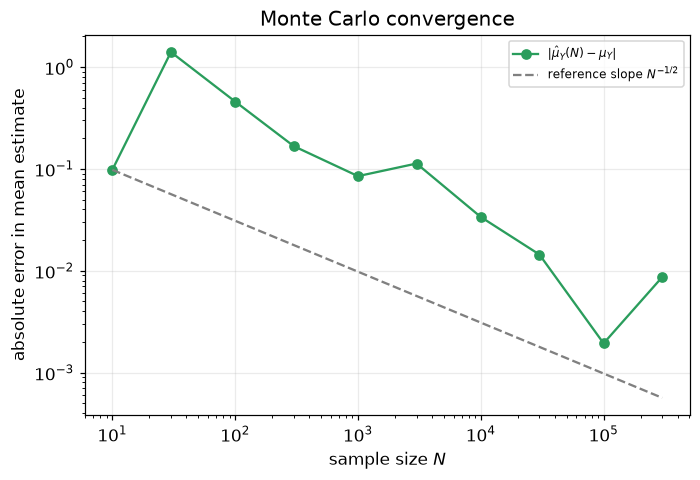

(one particular random draw -- the trend, not every wiggle, is the point)


In [4]:
Ns = np.array([10, 30, 100, 300, 1_000, 3_000, 10_000, 30_000, 100_000, 300_000])
mean_estimates = []
for Nn in Ns:
    X1n = rng.normal(mu1, sigma1, Nn)
    X2n = rng.normal(mu2, sigma2, Nn)
    mean_estimates.append(g(X1n, X2n).mean())
mean_estimates = np.array(mean_estimates)
abs_err = np.abs(mean_estimates - mu_Y_exact)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.loglog(Ns, abs_err, "o-", color=COLORS["mc"], label=r"$|\hat\mu_Y(N)-\mu_Y|$")
ref = abs_err[0] * np.sqrt(Ns[0] / Ns)
ax.loglog(Ns, ref, "--", color="gray", label=r"reference slope $N^{-1/2}$")
ax.set(xlabel="sample size $N$", ylabel="absolute error in mean estimate",
       title="Monte Carlo convergence")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("(one particular random draw -- the trend, not every wiggle, is the point)")

The error broadly tracks the $N^{-1/2}$ reference line (some wiggle is expected
from a single random draw at each $N$): quadrupling $N$ roughly halves the error.
This is the fundamental Monte Carlo trade-off -- accuracy is cheap to reason
about, but expensive to buy, *regardless of how many uncertain inputs there are*.
That dimension-independence is MCS's biggest advantage over methods that scale
poorly with the number of random variables, and its slow $N^{-1/2}$ rate is its
biggest cost, especially when $g$ itself is an expensive simulation.

---
## 4. Where FOSM breaks down: growing input variability

FOSM linearizes at the mean and never looks at $\sigma_1$ when computing the
gradient -- so as $\sigma_1$ (and hence $X_1$'s coefficient of variation
$\sigma_1/\mu_1$) grows, the terms FOSM ignores in Section 2 become relatively
more important.

> **Predict:** will FOSM's variance *relative* error stay roughly constant as
> $\sigma_1/\mu_1$ grows, or will it grow too?

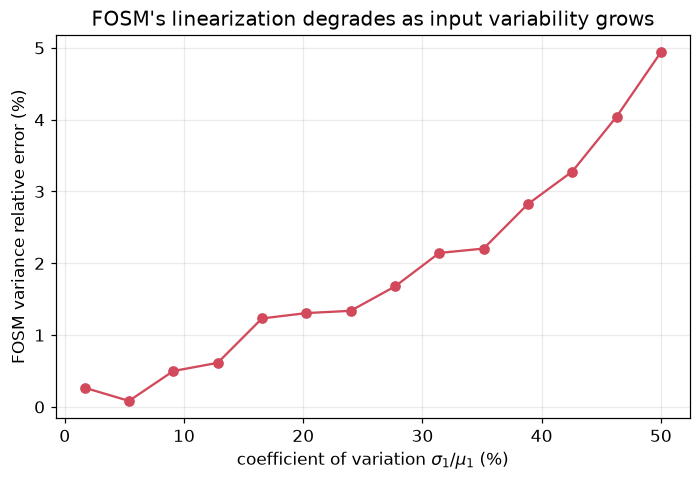

relative error at CoV=2%: 0.27%
relative error at CoV=50%: 4.94%


In [5]:
sigma1_values = np.linspace(0.05, 1.5, 14)
rel_err = []
for s1 in sigma1_values:
    X1n = rng.normal(mu1, s1, 300_000)
    X2n = rng.normal(mu2, sigma2, 300_000)
    var_mc = g(X1n, X2n).var(ddof=1)
    grad_here = grad_g(mu1, mu2)  # FOSM always linearizes at the (fixed) mean
    var_fosm = grad_here[0] ** 2 * s1 ** 2 + grad_here[1] ** 2 * sigma2 ** 2
    rel_err.append(abs(var_fosm - var_mc) / var_mc)
rel_err = np.array(rel_err)
cov1 = sigma1_values / mu1

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(100 * cov1, 100 * rel_err, "o-", color=COLORS["fosm"])
ax.set(xlabel=r"coefficient of variation $\sigma_1/\mu_1$ (%)",
       ylabel="FOSM variance relative error (%)",
       title="FOSM's linearization degrades as input variability grows")
plt.tight_layout(); plt.show()

print(f"relative error at CoV={cov1[0]*100:.0f}%: {100*rel_err[0]:.2f}%")
print(f"relative error at CoV={cov1[-1]*100:.0f}%: {100*rel_err[-1]:.2f}%")

The relative error grows steadily with $\sigma_1/\mu_1$: FOSM stays cheap (one
gradient evaluation) but its accuracy is only good for small, well-behaved input
variability and mild nonlinearity. This is exactly the trade-off the slides
flag -- MCS is accurate but expensive, FOSM is cheap but only locally valid.
FORM (next notebook) is the method built specifically to get MCS-quality *tail*
probabilities without paying MCS's full sampling cost.

---
## Takeaways

1. A Monte Carlo sample recovers a random variable's mean/variance/PDF directly,
   with no assumption on the function shape, at the cost of needing many samples
   -- error shrinks like $N^{-1/2}$, independent of the number of uncertain inputs.
2. FOSM's zeroth-order mean $g(\boldsymbol\mu)$ is biased by exactly the curvature
   term $\tfrac12\sum_i\partial^2g/\partial x_i^2\,\sigma_i^2$ that a second-order
   correction restores -- exactly, for a quadratic $g$; approximately otherwise.
3. FOSM's variance formula only sees the gradient at the mean, so it misses
   variance contributions from a random variable's own nonlinear terms and from
   covariances induced by nonlinear coupling between inputs.
4. FOSM's accuracy degrades as the input coefficient of variation grows -- a cheap
   method is only useful once you know its blind spots.

## Classroom exercises

1. Replace $g$ with the purely additive $g(x_1,x_2)=x_1^2+x_2^2$ (no $X_1X_2$
   cross-term) and repeat Section 2 -- does the FOSM variance gap shrink?
2. Swap $X_1$ for a lognormal random variable with the same mean and standard
   deviation and repeat Section 1 -- do the FOSM formulas (which only use
   $\mu,\sigma$) still make sense as an approximation for a skewed input?
3. Using the central-limit-theorem estimate $\sigma_Y/\sqrt N$ for the standard
   error of the mean, predict how many samples $N$ are needed for the 95%
   confidence interval on $\hat\mu_Y$ to be narrower than $0.01$, then check
   against Section 3's empirical curve.